In [1]:
import os
import numpy as np
from pydrake.geometry import Meshcat
import sys
from pydrake.visualization import VisualizationConfig, ApplyVisualizationConfig
from volta.prelude import *
from volta.test_objects import *
meshcat = Meshcat()


INFO:drake:Meshcat listening for connections at http://localhost:7000


In [2]:
# from pydrake.common.value import Value
# from pydrake.multibody.plant import ContactResults
# from pydrake.systems.framework import LeafSystem

# class ContactReporter(LeafSystem):
#     def __init__(self,plant):
#         super().__init__()  # Don't forget to initialize the base class.
#         self.plant = plant
#         self.DeclareAbstractInputPort(
#             name="contact_results",
#             model_value=Value(
#                 # Input port will take ContactResults from MultibodyPlant
#                 ContactResults()))
#         # Calling `ForcedPublish()` will trigger the callback.
#         self.DeclareForcedPublishEvent(self.Publish)
        
#     def Publish(self, context):
#         print()
#         print(f"ContactReporter::Publish() called at time={context.get_time()}")
#         contact_results:ContactResults = self.get_input_port().Eval(context)
        
#         num_hydroelastic_contacts = contact_results.num_hydroelastic_contacts()
#         print(f"num_hydroelastic_contacts() = {num_hydroelastic_contacts}")
        
#         for c in range(num_hydroelastic_contacts):
#             print()
#             print("-"*40)
#             print(f"hydroelastic_contact_info({c}): {c}-th hydroelastic contact patch")
#             hydroelastic_contact_info = contact_results.hydroelastic_contact_info(c)
#             hydroelastic_contact_info
#             spatial_force = hydroelastic_contact_info.F_Ac_W()
#             print("F_Ac_W(): spatial force (on body A, at centroid of contact surface, in World frame) = ")
#             print(f"{spatial_force}")
                        
#             print("contact_surface()")
#             contact_surface = hydroelastic_contact_info.contact_surface()
#             num_faces = contact_surface.num_faces()
#             total_area = contact_surface.total_area()
#             centroid = contact_surface.centroid()
#             # Get the raw GeometryIds for the two colliding shapes (M and N)
#             geom_id_M = contact_surface.id_M()
#             geom_id_N = contact_surface.id_N()
            
#             # Use the plant to find which Body owns which GeometryId
#             body_M = self.plant.GetBodyFromCollisionGeometry(geom_id_M)
#             body_N = self.plant.GetBodyFromCollisionGeometry(geom_id_N)
#             print(f"COLLISION BETWEEN: '{body_M.name()}' AND '{body_N.name()}'")
#             print(f"total_area(): area of contact surface in m^2 = {total_area}")
#             print(f"num_faces(): number of polygons or triangles = {num_faces}")
#             print(f"centroid(): centroid (in World frame) = {centroid}")        
        
#         print()

# def add_contact_report(builder, plant):   
#     contact_reporter = builder.AddSystem(ContactReporter(plant=plant))    
#     builder.Connect(plant.get_contact_results_output_port(),
#                     contact_reporter.get_input_port(0))
#     return builder, plant

In [3]:
from pydrake.common.value import Value
from pydrake.multibody.plant import ContactResults, MultibodyPlant
from pydrake.multibody.tree import BodyIndex
from pydrake.systems.framework import LeafSystem

class ContactReporter(LeafSystem):
    def __init__(self, plant: MultibodyPlant):
        super().__init__()  # Don't forget to initialize the base class.
        self.DeclareAbstractInputPort(
            name="contact_results",
            model_value=Value(
                # Input port will take ContactResults from MultibodyPlant
                ContactResults()))
        # Calling `ForcedPublish()` will trigger the callback.
        self.DeclareForcedPublishEvent(self.Publish)

        self._plant = plant
        self._geom_id_to_body_name = {}
        for i in range(self._plant.num_bodies()):
            body = self._plant.get_body(BodyIndex(i))
            if self._plant.geometry_source_is_registered():
                 for geom_id in self._plant.GetCollisionGeometriesForBody(body):
                    self._geom_id_to_body_name[geom_id] = body.name()
        
    def Publish(self, context):
        print()
        print(f"ContactReporter::Publish() called at time={context.get_time()}")
        contact_results:ContactResults = self.get_input_port().Eval(context)
        
        num_hydroelastic_contacts = contact_results.num_hydroelastic_contacts()
        print(f"num_hydroelastic_contacts() = {num_hydroelastic_contacts}")
        
        for c in range(num_hydroelastic_contacts):
            print()
            print("-"*40)
            print(f"hydroelastic_contact_info({c}): {c}-th hydroelastic contact patch")
            hydroelastic_contact_info = contact_results.hydroelastic_contact_info(c)
            
            contact_surface = hydroelastic_contact_info.contact_surface()
            body_A_name = self._geom_id_to_body_name.get(contact_surface.id_M(), "Unknown")
            body_B_name = self._geom_id_to_body_name.get(contact_surface.id_N(), "Unknown")
            print(f"Contact between: {body_A_name} and {body_B_name}")

            spatial_force = hydroelastic_contact_info.F_Ac_W()
            print("F_Ac_W(): spatial force (on body A, at centroid of contact surface, in World frame) = ")
            print(f"{spatial_force}")
                        
            print("contact_surface()")
            num_faces = contact_surface.num_faces()
            total_area = contact_surface.total_area()
            centroid = contact_surface.centroid()
            print(f"total_area(): area of contact surface in m^2 = {total_area}")
            print(f"num_faces(): number of polygons or triangles = {num_faces}")
            print(f"centroid(): centroid (in World frame) = {centroid}")        
        
        print()

def add_contact_report(builder, plant):   
    contact_reporter = builder.AddSystem(ContactReporter(plant))    
    builder.Connect(plant.get_contact_results_output_port(),
                    contact_reporter.get_input_port(0))
    return builder, plant

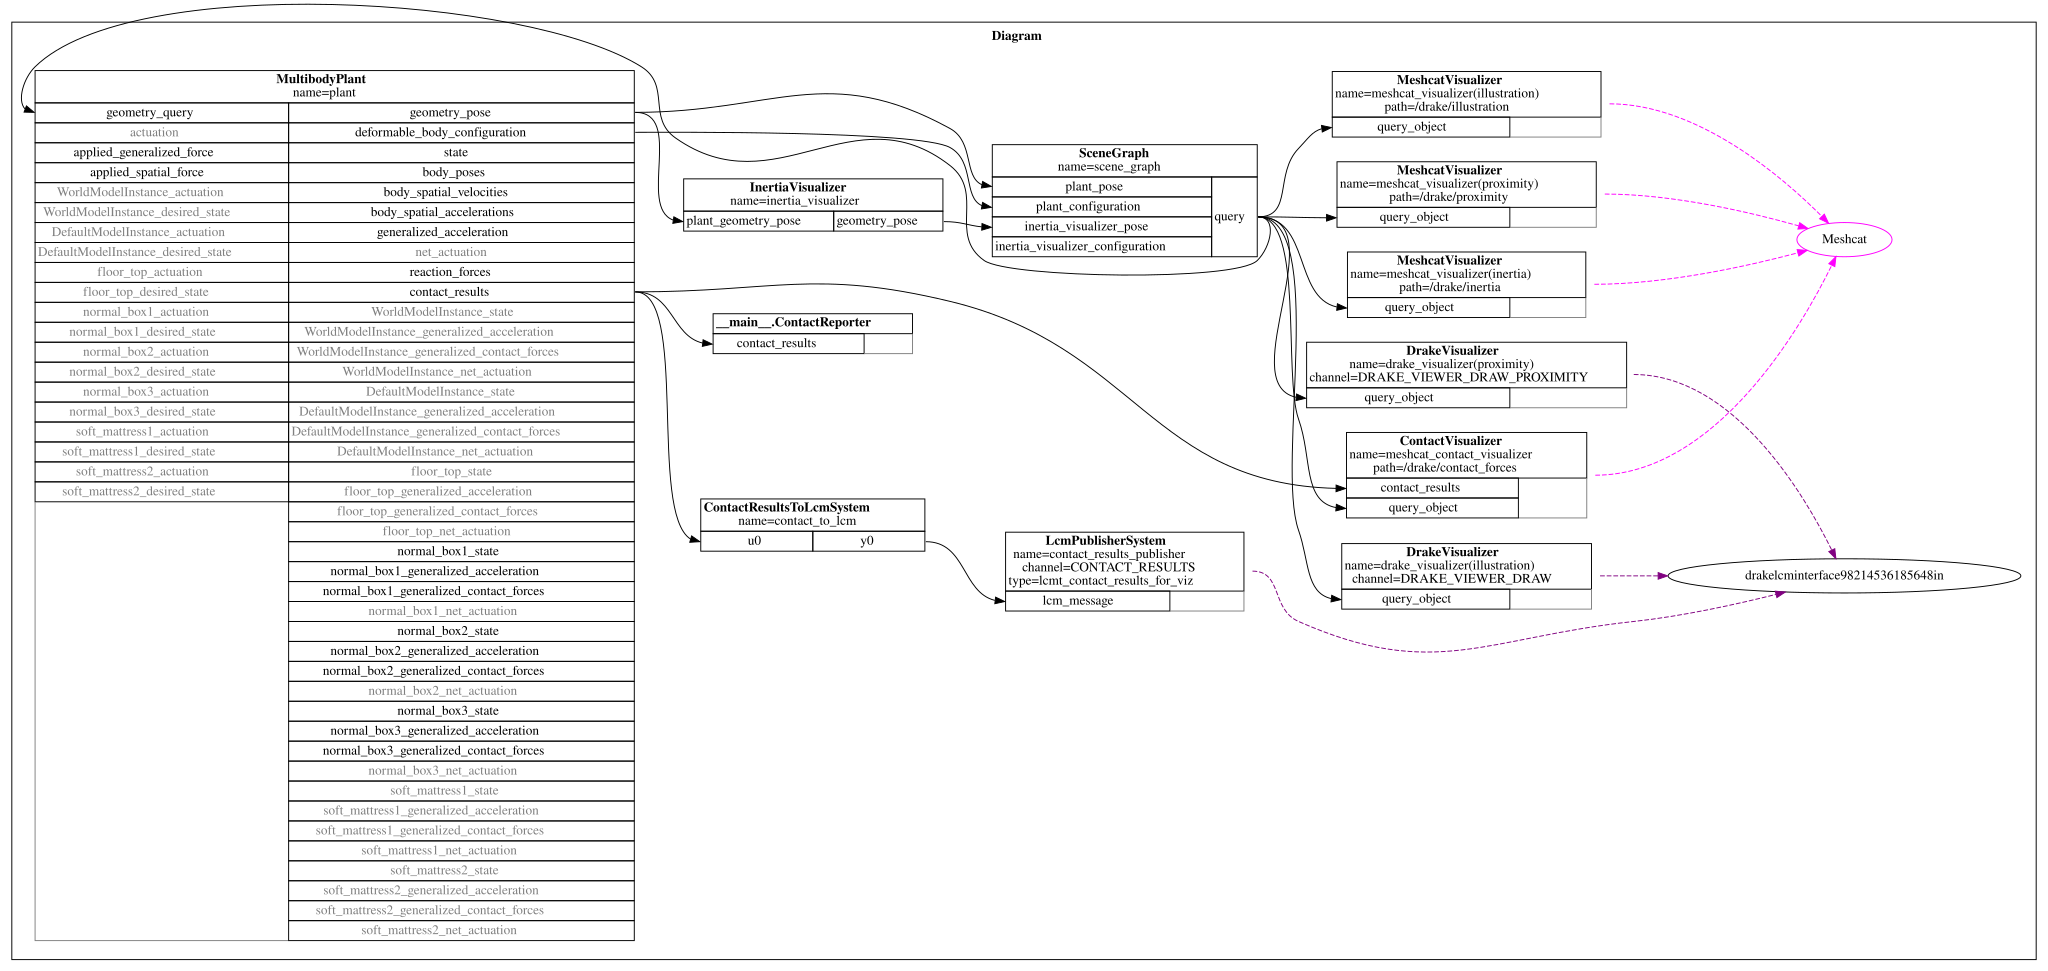

In [4]:
meshcat.Delete()
meshcat.DeleteAddedControls()
from pydrake.multibody.plant import AddMultibodyPlant, MultibodyPlantConfig
dir = "/home/tanawatp/Documents/Thesis_simulation/Models"


floor_sdf = "floor_top.sdf"
floor_sdf_path = os.path.join(dir,floor_sdf)

builder = DiagramBuilder()
# plant, scene_graph = AddMultibodyPlantSceneGraph(
#     builder, time_step=0.001)
plant, scene_graph = AddMultibodyPlant(
    MultibodyPlantConfig(
        time_step=0.0001,
        discrete_contact_approximation="similar"),
    builder)
plant:MultibodyPlant = plant
parser = Parser(plant)

# Add models to multibody plant
box_mass = 10.0
floor_idx               = parser.AddModels(floor_sdf_path)
# rigid_hydro_box_idx     = parser.AddModelsFromString(CompliantHydroBox(hydroelastic_modulus="1e5",mass=box_mass,name="compliant_hydro_box1"), "sdf")
# compliant_hydro_box_idx = parser.AddModelsFromString(CompliantHydroBox(hydroelastic_modulus="1e7",mass=box_mass), "sdf")
normal_box1_idx          = parser.AddModelsFromString(NormalBox(mass=box_mass,name="normal_box1"), "sdf")
normal_box2_idx          = parser.AddModelsFromString(NormalBox(mass=box_mass,name="normal_box2"), "sdf")
normal_box3_idx          = parser.AddModelsFromString(NormalBox(mass=box_mass,name="normal_box3"), "sdf")
soft_mattress1_prop  = SoftMattressProperties()
soft_mattress1_prop.modulus = "2e3"
soft_mattress1_prop.dissipation = "10"
soft_mattress1_idx   = parser.AddModelsFromString(SoftMattress(properties=soft_mattress1_prop,name="soft_mattress1"), "sdf")
soft_mattress2_prop  = SoftMattressProperties()
soft_mattress2_prop.modulus = "2e3"
soft_mattress2_prop.dissipation = "50"
soft_mattress2_idx   = parser.AddModelsFromString(SoftMattress(properties=soft_mattress2_prop,name="soft_mattress2"), "sdf")
# Weld the floor to the world so that it's fixed during the simulation.
floor_frame = plant.GetFrameByName("floor_top_center")
temp0 = RigidTransform(
    RollPitchYaw([0,0,0]), p=[0.0,0,0])
plant.WeldFrames(plant.world_frame(), 
                 floor_frame,
                 temp0)
matt_frame1 = plant.GetFrameByName("soft_mattress1_link")
X_FloorMat = RigidTransform(p=[0.0, 0.0, 0.1])
plant.WeldFrames(floor_frame, matt_frame1, X_FloorMat)
matt_frame2 = plant.GetFrameByName("soft_mattress2_link")
X_FloorMat = RigidTransform(p=[0.41, 0.0, 0.1])
plant.WeldFrames(floor_frame, matt_frame2, X_FloorMat)
plant.Finalize()

bulder, plant = add_contact_report(builder=builder,plant=plant)
# Set initial pose of robot
vis_config = VisualizationConfig()
vis_config.publish_contacts = True
ApplyVisualizationConfig(vis_config, builder, meshcat=meshcat)
diagram = builder.Build()

simulator = Simulator(diagram)
new_context = diagram.CreateDefaultContext()
simulator.reset_context(new_context)
context = simulator.get_mutable_context()
plant_context = plant.GetMyContextFromRoot(context)

# rigid_hydro_box = plant.GetBodyByName("rigid_hydro_box_link",rigid_hydro_box_idx[0])
# rigid_hydro_box = plant.GetBodyByName("compliant_hydro_box1_link",rigid_hydro_box_idx[0])
# roll = 0.0
# W_T_box = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[-0.2, -0.1, 2.2])
# plant.SetFreeBodyPose(plant_context, rigid_hydro_box, W_T_box)

# compliant_hydro_box = plant.GetBodyByName("compliant_hydro_box_link",compliant_hydro_box_idx[0])
# roll = 0.0
# W_T_box = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[0.0, 0, 2.2])
# plant.SetFreeBodyPose(plant_context, compliant_hydro_box, W_T_box)

# normal_box = plant.GetBodyByName("normal_box_link",normal_box_idx[0])
# roll = 0.0
# W_T_box = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[0.2, 0.1, 2.2])
# plant.SetFreeBodyPose(plant_context, normal_box, W_T_box)
normal_box1 = plant.GetBodyByName("normal_box1_link",normal_box1_idx[0])
roll = 20.0
W_T_box1 = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[-0.2, -0.35, 2.2])
plant.SetFreeBodyPose(plant_context, normal_box1, W_T_box1)
normal_box2 = plant.GetBodyByName("normal_box2_link",normal_box2_idx[0])
roll = 20.0
W_T_box2 = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[0.0, 0, 2.2])
plant.SetFreeBodyPose(plant_context, normal_box2, W_T_box2)
normal_box3 = plant.GetBodyByName("normal_box3_link",normal_box3_idx[0])
roll = 20.0
W_T_box3 = RigidTransform(rpy=RollPitchYaw(np.array([roll,0.0,0.0])*np.pi/180.0),p=[0.4, 0.0, 2.2])
plant.SetFreeBodyPose(plant_context, normal_box3, W_T_box3)
show_diagram(diagram=diagram,show=True)

In [5]:

# Simulate
simulator.Initialize()
# simulator.set_target_realtime_rate(1.0)
meshcat.StartRecording()
print("Simulating... The sphere will fall onto the rubber mat.")
simulator.AdvanceTo(2.5)
print("Simulation complete.")
meshcat.StopRecording()

# Numerically report contact results at the end of simulation.
diagram.ForcedPublish(simulator.get_context())
meshcat.PublishRecording()

Simulating... The sphere will fall onto the rubber mat.
Simulation complete.

ContactReporter::Publish() called at time=2.5
num_hydroelastic_contacts() = 0

